In [1]:
import pandas as pd
data = pd.read_csv("calibration_data.csv")
data.head()

,Sample,Time_ms,Ax_g,Ay_g,Az_g
0,1,0,0.064453,0.015869,1.029541
1,2,10,0.063477,0.015137,1.024658
2,3,20,0.064697,0.017090,1.020752
3,4,30,0.062988,0.016602,1.031006
4,5,40,0.067383,0.016846,1.028320


In [4]:
expected = set(range(1, 12001))
received = set(data["Sample"])

missing = sorted(expected - received)

print("Number of missing samples:", len(missing))
print("Missing samples:", missing)

Number of missing samples: 14
Missing samples: [117, 118, 119, 120, 121, 122, 123, 124, 125, 126, 127, 128, 129, 130]


In [6]:
data.tail()

,Sample,Time_ms,Ax_g,Ay_g,Az_g
11982,11996,119950,0.064941,0.016357,1.027344
11983,11997,119960,0.065430,0.014893,1.027100
11984,11998,119970,0.062012,0.017822,1.026367
11985,11999,119980,0.065430,0.017334,1.026367
11986,12000,119990,0.065186,0.015625,1.024170


In [7]:
data["Sample"].duplicated().sum()

np.int64(1)

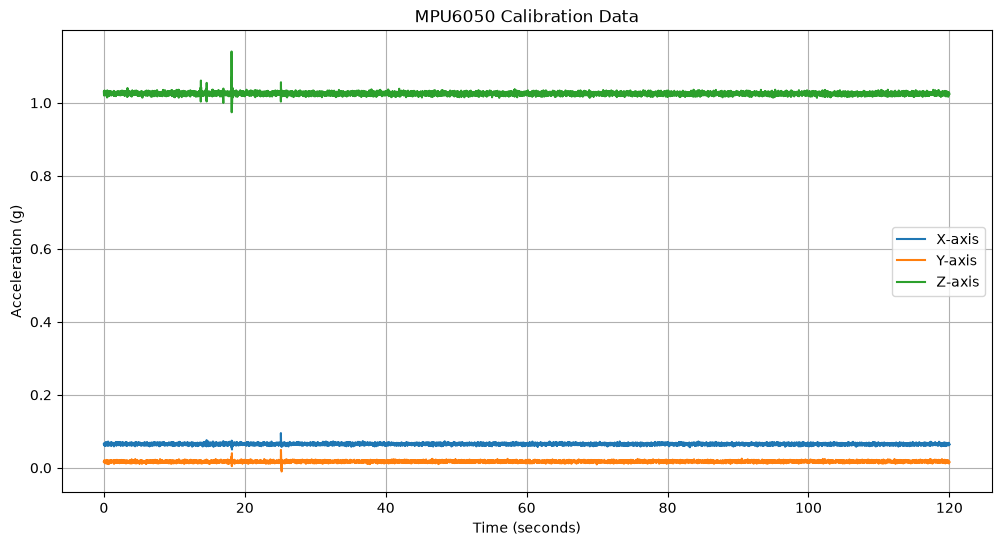

In [8]:
# Sensor behavior over the 2-minute calibration period.
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.plot(data["Time_ms"] / 1000, data["Ax_g"], label="X-axis")
plt.plot(data["Time_ms"] / 1000, data["Ay_g"], label="Y-axis")
plt.plot(data["Time_ms"] / 1000, data["Az_g"], label="Z-axis")

plt.xlabel("Time (seconds)")
plt.ylabel("Acceleration (g)")
plt.title("MPU6050 Calibration Data")
plt.legend()
plt.grid()

plt.show()

In [16]:
# Calculate noise by removing the mean of each axis
noise_x = data["Ax_g"] - data["Ax_g"].mean()
noise_y = data["Ay_g"] - data["Ay_g"].mean()
noise_z = data["Az_g"] - data["Az_g"].mean()

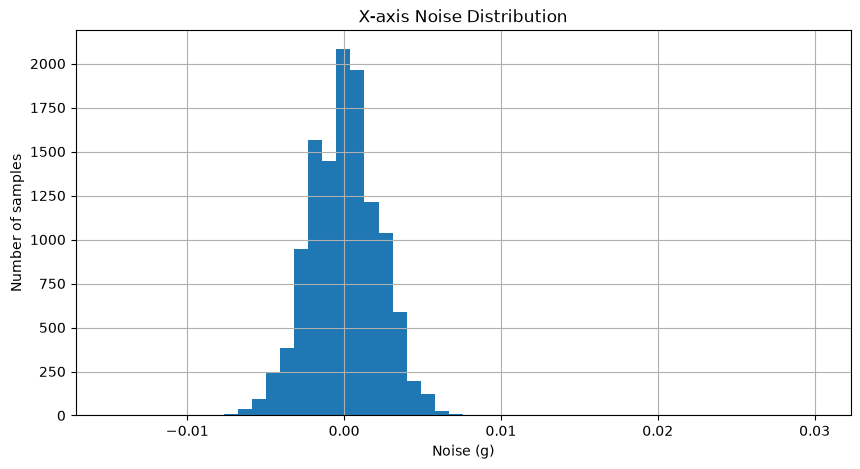

In [10]:
# X-axis noise distribution
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.hist(noise_x, bins=50)

plt.xlabel("Noise (g)")
plt.ylabel("Number of samples")
plt.title("X-axis Noise Distribution")
plt.grid()

plt.show()

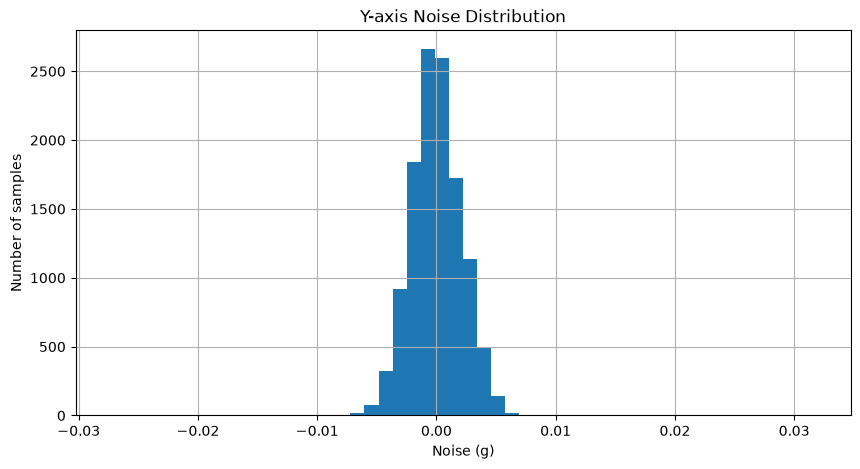

In [11]:
# Y-axis noise distribution
plt.figure(figsize=(10, 5))

plt.hist(noise_y, bins=50)

plt.xlabel("Noise (g)")
plt.ylabel("Number of samples")
plt.title("Y-axis Noise Distribution")
plt.grid()

plt.show()

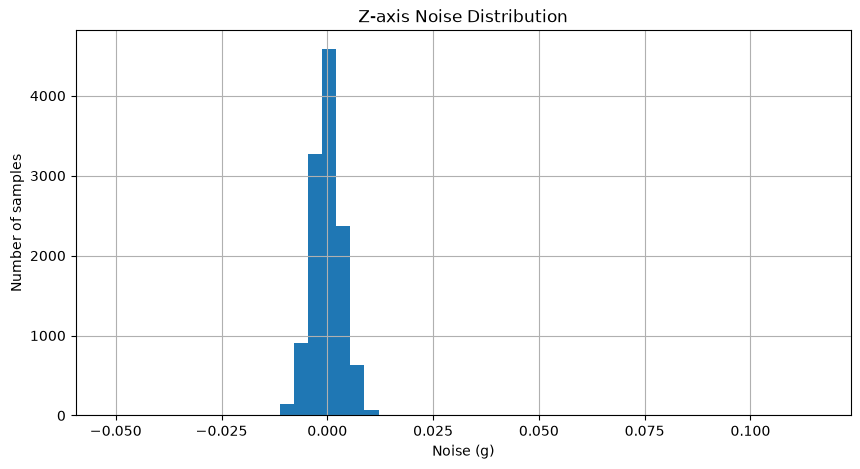

In [12]:
# Z-axis noise distribution
plt.figure(figsize=(10, 5))

plt.hist(noise_z, bins=50)

plt.xlabel("Noise (g)")
plt.ylabel("Number of samples")
plt.title("Z-axis Noise Distribution")
plt.grid()

plt.show()

In [13]:
print("Noise statistics")
print("-----------------")

print(f"X-axis mean noise: {noise_x.mean():.8f} g")
print(f"X-axis std dev:    {noise_x.std():.8f} g")

print(f"Y-axis mean noise: {noise_y.mean():.8f} g")
print(f"Y-axis std dev:    {noise_y.std():.8f} g")

print(f"Z-axis mean noise: {noise_z.mean():.8f} g")
print(f"Z-axis std dev:    {noise_z.std():.8f} g")

Noise statistics
-----------------
X-axis mean noise: 0.00000000 g
X-axis std dev:    0.00220903 g
Y-axis mean noise: 0.00000000 g
Y-axis std dev:    0.00218556 g
Z-axis mean noise: 0.00000000 g
Z-axis std dev:    0.00378260 g


In [14]:
# Baseline values obtained during calibration
baseline_x = data["Ax_g"].mean()
baseline_y = data["Ay_g"].mean()
baseline_z = data["Az_g"].mean()

# Remove the stationary baseline
data["Ax_corrected"] = data["Ax_g"] - baseline_x
data["Ay_corrected"] = data["Ay_g"] - baseline_y
data["Az_corrected"] = data["Az_g"] - baseline_z

data.head()

,Sample,Time_ms,Ax_g,Ay_g,Az_g,Ax_corrected,Ay_corrected,Az_corrected
0,1,0,0.064453,0.015869,1.029541,-0.000712,-0.001425,0.004264
1,2,10,0.063477,0.015137,1.024658,-0.001688,-0.002157,-0.000619
2,3,20,0.064697,0.017090,1.020752,-0.000468,-0.000204,-0.004525
3,4,30,0.062988,0.016602,1.031006,-0.002177,-0.000692,0.005729
4,5,40,0.067383,0.016846,1.028320,0.002218,-0.000448,0.003043


In [15]:
print("Corrected means:")
print(f"X: {data['Ax_corrected'].mean():.8f} g")
print(f"Y: {data['Ay_corrected'].mean():.8f} g")
print(f"Z: {data['Az_corrected'].mean():.8f} g")

Corrected means:
X: 0.00000000 g
Y: 0.00000000 g
Z: 0.00000000 g
